# Numerical Computation of Action-variables

0. Get a potential V(x)
1. Mesh of the energy
2. Identification of the turning points at each energy level (Newton root)
3. Identification of equilibrium points
4. Label alphabethically the separatrix regions
5. Index the orbits (there could be energy degeneracy)
6. Resolve the energy degeneracy using the regions' labeling
7. Compute $J$, and $\omega$ for each orbit

[1] Berg and Warnock


In [2]:
import numpy as np
from matplotlib import pyplot as plt
import pandas as pd

# The Hamiltonian

In [3]:
def potential(q):
    return q**4/2 - q**2 + 0.5

# Numerical method: three classes (Ham, Regions, Trajectory)

- input: Energy levels and potential
- output: Separatrix regions, and trajectories with energy degeneracy

### Utility functions

In [4]:
def Newton_root(f, q_0, tol, max_iter):
    q = q_0
    for i in range(max_iter):
        f_q = f(q)
        f_prime_q = (f(q + tol) - f(q - tol)) / (2*tol)  # Numerical derivative
        if abs(f_prime_q) < tol:
            # if the derivative is small, we are close to a stationary point
            # Let's find the max/min and see if it is a root (or close enought to it)
            f_prime = lambda q: (f(q + tol) - f(q - tol)) / (2*tol)
            q_new = Newton_root(f_prime, q, tol=tol, max_iter=max_iter)
            if abs(q_new - q) < tol:
                if abs(f(q_new)) < tol:
                    return q_new
                else:
                    return None
        q_new = q - f_q / f_prime_q
        if abs(q_new - q) < tol:
            return q_new
        q = q_new
    raise ValueError("Newton's method did not converge within the maximum number of iterations.")

def root_guess(f, qmin, qmax, Nq):
    # sample [qmin, qmax] in many points
    # if |f(xi)|<|f(x{i-1})|, |f(x{i+1})|, xi is a good guess
    # Return: np.array of dim n (number of roots)
    qj = np.linspace(qmin, qmax, Nq)
    fj = f(qj)
    root=[]
    i=0
    for i in range(1, Nq-1):
        if np.abs(fj[i])<np.abs(fj[i-1]) and np.abs(fj[i])<np.abs(fj[i+1]):
            root.append(qj[i])
    return np.array(root)

def alphabeth(j):
    word = ''
    letters = np.array(['a','b','c','d','e','f','g','h','i','j','k','l','m','n','o','p','q','r','s','t','u','v','w','x','y','z'], dtype='<U1')
    while j > 0:
        u = np.mod(j-1, 26) 
        word =  letters[u] + word
        j = int((j-u)/26)
    return word

def q_u(u, q0, q1):
    return q0/2*(1+np.cos(u)) + q1/2*(1-np.cos(u))

def u_q(q, q0, q1):
    return np.arccos((q0+q1-2*q)/(q1-q0))

def simpson(y, dx):
    integral = dx/3*(y[0] + y[len(y)-1])
    for i in range(1, int((len(y)-1)/2)):
        integral = integral + 4*dx/3* y[2*i - 1]
    for i in range(1, int((len(y)-1)/2-1)):
        integral = integral + 2*dx/3*y[2*i]
    return integral

### Class Ham

In [5]:
class Ham:
  def __init__(self, V, E, x):
    ''' V: the potential function \\
     E: energy levels \\
     x: position grid \\
     trajec: list of trajectories \\
     reg: list of regions to solve the energy degeneracy \\'''

    self.V = V
    self.E = E
    self.x = x
    self.xmin = np.min(x)
    self.xmax = np.max(x)
    self.equi_point = {'x': [], 'V': [], 'kind': []}

    # first guess roots parameters
    self.Nq_root=len(x)

    # root finding parameters
    self.tol=1e-6
    self.max_iter=100

    # integral in phase space
    self.Nu = 1001

  def p(self,qi,Ei):
    return np.real(np.sqrt(2*Ei - 2*self.V(qi), dtype=complex))

  def turns(self):
    self.root = []
    for i in range(0, len(self.E)):
      f = lambda q: 2*self.E[i] - 2*self.V(q)
      self.root.append(root_guess(f, self.xmin, self.xmax, self.Nq_root))
      # find the root with newton
      for j in range(0, len(self.root[i])):
        self.root[i][j]  = Newton_root(f, self.root[i][j], self.tol, self.max_iter)
      # Remove the root if it is not valid
      self.root[i] =  self.root[i][~np.isnan(self.root[i])] 

  def equilibrium(self):
    # find the roots for each energy values
    f = lambda q: (self.V(q+self.tol) - self.V(q-self.tol))/(2*self.tol)
    self.equi_point['x'] = np.array(root_guess(f, self.xmin, self.xmax, self.Nq_root))
    # find the root with newton
    for j in range(len(self.equi_point['x'])):
      self.equi_point['x'][j]  = Newton_root(f, self.equi_point['x'][j], self.tol, self.max_iter)
    self.equi_point['x'] =  self.equi_point['x'][~np.isnan(self.equi_point['x'])]  # Remove the root if it is not valid

    self.equi_point['V'] = np.array([self.V(xi) for xi in self.equi_point['x']])
  
    self.equi_point['kind'] = []
    for xi in self.equi_point['x']:
      if self.V(xi) > self.V(xi-2*self.tol):
        self.equi_point['kind'].append('max')
      elif self.V(xi) < self.V(xi-2*self.tol):
        self.equi_point['kind'].append('min')
      else:
        raise ValueError("The point is neither a maximum nor a minimum.")
    self.equi_point['kind'] = np.array(self.equi_point['kind'])
    
  def get_regions(self):
    self.reg = Regions(self)
    self.reg.add_boundaries(self)
    while self.reg.points['x'].size > 2:
      self.reg.find_region()
    self.reg.deletepoint(1)
    self.reg.deletepoint(0)

  def get_trajectories(self):
    self.trajec = Trajectories()
    self.trajec.fill(self)
    self.trajec.getlabel(self.reg)
    
  def get_actionfreq(self)
    self.trajec.computeJ(self)
    self.trajec.computeomega(self)

SyntaxError: expected ':' (3338160560.py, line 74)

### Class Regions

In [6]:
class Regions:
  def __init__(self, ham):
    self.label = []
    self.Emin = []
    self.Emax = []
    self.xmin = []
    self.xmax = []
    self.points = {'x': [], 'V': [], 'kind': []}
    self.points['x'] = ham.equi_point['x']
    self.points['V'] = ham.equi_point['V']
    self.points['kind'] = ham.equi_point['kind']
    #self.points = self.add_boundaries(ham)
    # del self.points

  def add_boundaries(self, ham):
    self.points['x'] = np.concatenate([[ham.xmin], self.points['x'], [ham.xmax]])
    self.points['V'] = np.concatenate([[ham.V(ham.xmin)], self.points['V'], [ham.V(ham.xmax)]])
    self.points['kind'] = np.concatenate([['boundary'], self.points['kind'], ['boundary']])

  def find_region(self):
    # build the regions in phase-space starting from the lowest energy. If neighborh points have the same energy, they lie on the same separatrix, thus we have only one region. 
    # The method discard the first point and work with the other. After the region has been built, then the point is discarded
    j = len(self.label) + 1
    i = np.argmin(self.points['V'])
    if self.points['V'][i] == self.points['V'][i+1] or self.points['V'][i] == self.points['V'][i-1]:
      self.deletepoint(i)
    else:
      self.label.append(alphabeth(j))
      Emax, Emin = self.energy_range(i)
      self.Emax.append(Emax)
      self.Emin.append(Emin)
      xmax, xmin = self.position_range(i)
      self.xmax.append(xmax)
      self.xmin.append(xmin)
      self.deletepoint(i)

  def position_range(self, i):
    # at the lowest energy unexplored the position range is limited by the neighbors!
    xmin = self.points['x'][i-1]
    xmax = self.points['x'][i+1]
    return xmax, xmin
        
  def energy_range(self, i):
    # at the lowest energy explored, the energy is bounded by the lowest energy (the one of the point) and the lowest energy between the neigbohrs.
    Emin = self.points['V'][i]
    Emax = min(self.points['V'][i+1], self.points['V'][i-1])
    return Emax, Emin

  def deletepoint(self, i):
    for key, value in self.points.items():
      self.points[key] = np.delete(value, i)

  def df(self):
    return  pd.DataFrame( {key: self.__dict__[key] for key in ['xmin','xmax','Emin','Emax']} , index=self.label )

    

### Class Trajectories

In [7]:
class Trajectories:
  def __init__(self):
    self.index = np.array([], dtype=int)
    self.E = np.array([])
    self.x1 = np.array([])
    self.x2 = np.array([])
    self.label = np.array([])

  def fill(self, ham):
    k = 0 # index of the trajectory
    for i, qs in enumerate(ham.root):
      # i is the index of energy level
      for j, qi in enumerate(qs[:-1]):
        # j is the index of root at energy level Ei
        if ham.V(qi+ham.tol) < ham.E[i]:
            self.index = np.concatenate([self.index, [int(k)]], dtype=int)
            self.E = np.concatenate([self.E, [ham.E[i]] ])
            self.x1 = np.concatenate([self.x1, [qs[j]] ])
            self.x2 = np.concatenate([self.x2, [qs[j+1]] ])
            k += 1

  def getlabel(self, regions):
    for i in self.index:
      maskx1 = regions.xmin < self.x1[i]
      maskx2 = regions.xmax > self.x2[i]
      maskEmin = regions.Emin < self.E[i]
      maskEmax  = regions.Emax > self.E[i]
      mask = maskx1 & maskx2 & maskEmin & maskEmax
      self.label = np.concatenate([ self.label, np.array(regions.label)[mask] ])

  def computeJ(self, ham):
    self.J = np.array([])
    for i in self.index:
      self.J = np.concatenate([self.J, [self.Ji(ham,i) ]])

  def Ji(self, ham, i):
    uj = np.linspace(0, np.pi, ham.Nu)
    du = uj[1]-uj[0]
    qj = q_u(uj,self.x1[i],self.x2[i])
    pj = ham.p(qj, self.E[i])
    integrand_J = np.sin(uj)*pj
    return 1/np.pi*(self.x2[i]-self.x1[i])/2*simpson(integrand_J,du)

  def computeomega(self, ham):
    self.omega = np.zeros_like(self.J)
    for letter in ham.reg.label:
      mask = self.label == letter
      ind = self.index[mask]
      if len(ind) < 2: break

      self.omega[ind] = self.omega_letter(mask)

  def omega_letter(self,mask):
    om = []
    E = self.E[mask]
    J = self.J[mask]
    for i in range(len(E)):
      if i == 0:
        om.append( (E[1]-E[0])/(J[1]-J[0]) )
      elif i == len(E)-1:
        om.append( (E[-1]-E[-2])/(J[-1]-J[-2]) )
      else:
        om.append( (E[i+1]-E[i-1])/(J[i+1]-J[i-1]) )
    return np.array(om)

  def df(self):
      return  pd.DataFrame( {key: self.__dict__[key] for key in ['x1','x2','E','label', 'J', 'omega']} , index=self.index )
  

# Test

## test of the classes implementation

### test the turning points search

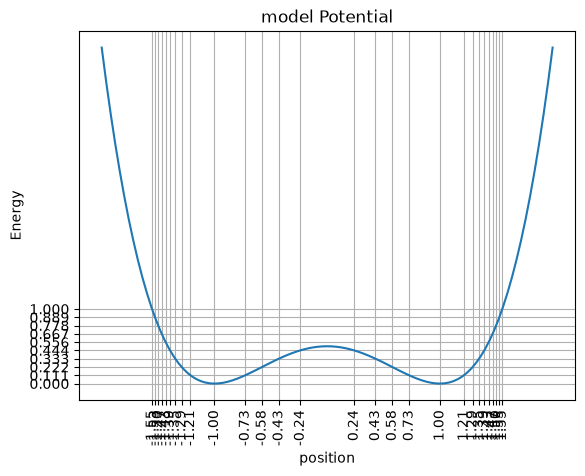

In [8]:
H0 = 0
H1 = 1
Ni = 10

H = np.linspace(H0, H1, Ni)
x = np.linspace(-2, 2, 101)

system = Ham(potential, H, x)

system.turns()

plt.plot(x, potential(x))
plt.title('model Potential')
plt.xlabel('position')
plt.ylabel('Energy')
plt.grid()
plt.yticks(H)
xtic = np.sort(np.concatenate(system.root))
plt.xticks(xtic, labels=[f'{x:.2f}' for x in xtic], rotation=90)
plt.show()

### test the equilibrium points

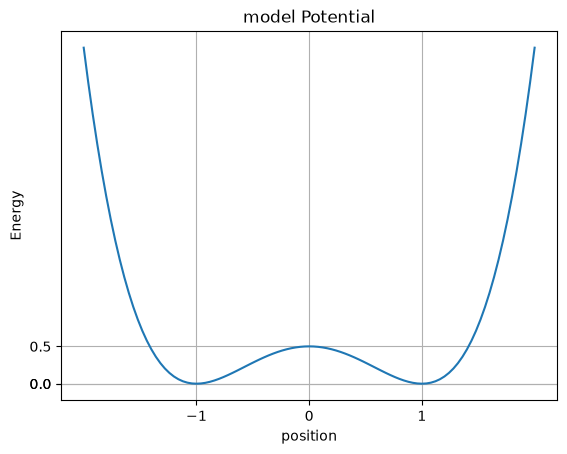

In [9]:
system.equilibrium()

plt.plot(x, potential(x))
plt.title('model Potential')
plt.xlabel('position')
plt.ylabel('Energy')
plt.grid()
plt.xticks(system.equi_point['x'])
ytic = np.sort(np.array(system.equi_point['V']))
plt.yticks(ytic)
plt.show()

### test the regions search

In [10]:
system.get_regions()
system.reg.df()

,xmin,xmax,Emin,Emax
a,-2.0,0.0,0.0,0.5
b,0.0,2.0,0.0,0.5
c,-2.0,2.0,0.5,4.5


### test trajectory finding and labeling

In [11]:
system.get_trajectories()
system.trajec.label

array(['a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'c', 'c', 'c', 'c', 'c'],
      dtype='<U32')

### test computing J and omega per trajectory

In [12]:
system.trajec.computeJ(system)
system.trajec.computeomega(system)

system.trajec.df()

,x1,x2,E,label,J,omega
0,-1.213015,-0.727046,0.111111,a,0.056819,1.854607
1,0.727046,1.213015,0.111111,b,0.056819,1.854607
2,-1.290994,-0.577350,0.222222,a,0.116730,1.787265
3,0.577350,1.290994,0.222222,b,0.116730,1.787265
4,-1.347775,-0.428373,0.333333,a,0.181156,1.620336
5,0.428373,1.347775,0.333333,b,0.181156,1.620336
6,-1.393847,-0.239146,0.444444,a,0.253876,1.527927
7,0.239146,1.393847,0.444444,b,0.253876,1.527927
8,-1.433211,1.433211,0.555556,c,0.691751,0.790313
9,-1.467890,1.467890,0.666667,c,0.832342,0.847330


## test of the numerical method (no classes)
1. Mesh of the energy
2. Identification of the turning points for an orbit (Newton root)
3. Test the method for one orbit:
    - Define the change of varible $u \rightarrow q$
    - Compute the integral $J$ (using a mesh on $u$)
    - Compute the integral $\Phi$ <i>(to be continued...)</i>
    - Test the convergence
4. Label the orbits
5. Group the orbits for each separatrix regions
6. Compute $J$, and $\omega$


### 1. Mesh grid for $H$: $H_i$

In [ ]:
H0 = 0
H1 = 1
Ni = 10

H = np.linspace(H0, H1, Ni)

### 2. Turning points $q_0$ and $q_1$

In [ ]:
def Newton_root(f, q_0, tol=1e-6, max_iter=100):
    q = q_0
    for i in range(max_iter):
        f_q = f(q)
        f_prime_q = (f(q + tol) - f(q - tol)) / (2*tol)  # Numerical derivative
        if abs(f_prime_q) < tol:
            # if the derivative is small, we are close to a stationary point
            # Let's find the max/min and see if it is a root (or close enought to it)
            f_prime = lambda q: (f(q + tol) - f(q - tol)) / (2*tol)
            q_new = Newton_root(f_prime, q, tol=tol, max_iter=max_iter)
            if abs(q_new - q) < tol:
                if abs(f(q_new)) < tol:
                    return q_new
                else:
                    return None
        q_new = q - f_q / f_prime_q
        if abs(q_new - q) < tol:
            return q_new
        q = q_new
    raise ValueError("Newton's method did not converge within the maximum number of iterations.")

def root_guess(f, qmin=-5, qmax=5, Nq=111):
    # sample [qmin, qmax] in many points
    # if |f(xi)|<|f(x{i-1})|, |f(x{i+1})|, xi is a good guess
    # Return: np.array of dim n (number of roots)
    qj = np.linspace(qmin, qmax, Nq)
    fj = f(qj)
    root=[]
    i=0
    for i in range(1, Nq-1):
        if np.abs(fj[i])<np.abs(fj[i-1]) and np.abs(fj[i])<np.abs(fj[i+1]):
            root.append(qj[i])
    return np.array(root)

In [ ]:
def turning_points(V, H,qmin=-5, qmax=5, Nq=111):
    q_root = []
    # find the roots for each energy values
    for i in range(0, len(H)):
        f = lambda q: 2*H[i] - 2*V(q)
        q_root.append(root_guess(f, qmin, qmax, Nq))
        # find the root with newton
        for j in range(0, len(q_root[i])):
            q_root[i][j]  = Newton_root(f, q_root[i][j])
        q_root[i] =  q_root[i][~np.isnan(q_root[i])]  # Remove the root if it is not valid
    return q_root


In [ ]:
root = turning_points(V, H)

In [ ]:
x = np.linspace(-1.5, 1.5, 100)
plt.plot(x, V(x))
plt.title('model Potential')
plt.xlabel('position')
plt.ylabel('Energy')
plt.grid()
plt.yticks(H)
xtic = np.sort(np.concatenate(root))
plt.xticks(xtic, labels=[f'{x:.2f}' for x in xtic], rotation=90)
plt.show()

### 3. Test on a case orbit

In [ ]:
i=4


- mesh on $u$

In [ ]:
Nu = 101

uj = np.linspace(0, np.pi, Nu)

- change of variable $q \rightarrow u$

In [ ]:
def q(u, q0, q1):
    return q0/2*(1+np.cos(u)) + q1/2*(1-np.cos(u))

def u(q, q0, q1):
    return np.arccos((q0+q1-2*q)/(q1-q0))

In [ ]:
qj = q(uj,root[i][0], root[i][1])
pj = p(qj, H[i])

In [ ]:
plt.scatter(qj, pj, label='half-orbit')
plt.scatter(qj, -pj)
plt.title('orbit for $H={:.1f}'.format(H[i]))
plt.xlabel('q')
plt.ylabel('p')
plt.legend()
plt.show()

- Computation of $J$ and $\Phi$ with Simpson method

- Computation of $J$ with Simpson method

In [ ]:
def q(u, q0, q1):
    return q0/2*(1+np.cos(u)) + q1/2*(1-np.cos(u))

def u(q, q0, q1):
    return np.arccos((q0+q1-2*q)/(q1-q0))

def simpson(y, dx):
    integral = dx/3*(y[0] + y[len(y)-1])
    for i in range(1, int((len(y)-1)/2)):
        integral = integral + 4*dx/3* y[2*i - 1]
    for i in range(1, int((len(y)-1)/2-1)):
        integral = integral + 2*dx/3*y[2*i]
    return integral

In [ ]:
du = uj[1]-uj[0]
integrand_J = np.sin(uj)*pj

J = 1/np.pi*(root[i][1]-root[i][0])/2*simpson(integrand_J,du)
print(" $J$ ",J)

- Computation of $\Phi$

<i> Test Richardons extrapolation to see if the integrand is converging.

<u> Note</u>: the integral for $\Phi$ is diverging at turning points </i>

In [ ]:
from math import nan

# extrapolation for limit

integrand_Phi =  np.sin(uj)/pj

# use the limit instead of the function where the integrand diverges
ind = np.where(pj==0)[0]
print('problematic points', len(ind))
lim = []
 
for j, index in enumerate(ind):  
    D = np.zeros((5,5))
    f = lambda x: np.sin(x)/p(q(x,root[i][0], root[i][1]), H[i])
    for n in range(0,5):
        D[n,0] = (f(uj[index] + du/2**n)-f(uj[index] - du/2**n))/(du/2**(n))
        for k in range(0,n):
            D[n,k+1] = D[n,k] + (D[n,k]-D[n-1,k])/(4**k-1)
    # print(D)
    if lim == nan :
        print('nan')
        lim.append()
    else:
        lim.append(D[-1,-1])
integrand_Phi[pj==0] = np.array(lim)


In [ ]:
du = uj[1]-uj[0]
integrand_Phi =  (np.sin(uj)/pj)[2:-2]
Phi = 1/np.pi*(root[i][1]-root[i][0])/2*simpson(integrand_Phi,du)
print("$/Phi$ ",Phi)

- compute $\Phi$: Newton-Coxe formulas

In [ ]:
# ... to be continued


- Convergence of the integrals

<i>what is the optimal $h$ in order to balance between Trucation error and Roundoff error?</i>

In [ ]:
machine_precision = np.finfo(float).eps
Nu = 2**np.arange(2, 20) + 1
J = np.zeros(len(Nu))
L = np.abs(root[i][0]- root[i][1]) # legnth of interval
for k,N in enumerate(Nu):
    uj= np.linspace(0, np.pi, N)
    qj = q(uj,root[i][0], root[i][1])
    pj = p(qj, H[i])  
    du = uj[1]-uj[0]
    integrand_J = np.sin(uj)*pj

    J[k] = 1/np.pi*(root[i][1]-root[i][0])/2*simpson(integrand_J,du)

plt.axhline(machine_precision, color='r', alpha=0.5, linestyle='--', label='Machine Precision')
plt.axvline(machine_precision, color='r', alpha=0.5, linestyle='--')
plt.scatter(L/Nu[:-1], np.abs(J[:-1]-J[1:]), label='Error')
plt.xlabel('h')
plt.ylabel('error - variation')
plt.xscale('log')
plt.yscale('log')
plt.title('Convergence of the $J$')
plt.legend()
plt.show()


In [ ]:
machine_precision = np.finfo(float).eps
Nu = 2**np.arange(2, 20) + 1
Phi = np.zeros(len(Nu))
L = np.abs(root[i][0]- root[i][1]) # legnth of interval
for k,N in enumerate(Nu):
    uj= np.linspace(0, np.pi, N)
    qj = q(uj,root[i][0], root[i][1])
    pj = p(qj, H[i])  
    du = uj[1]-uj[0]
    integrand_Phi = (np.sin(uj)/pj )[2:-2]

    Phi[k] = 1/np.pi*(root[i][1]-root[i][0])/2*simpson(integrand_Phi,du)

plt.axhline(machine_precision, color='r', alpha=0.5, linestyle='--', label='Machine Precision')
plt.axvline(machine_precision, color='r', alpha=0.5, linestyle='--')
plt.scatter(L/Nu[:-1], np.abs(Phi[:-1]-Phi[1:]), label='Error')
plt.xlabel('h')
plt.ylabel('error - variation')
plt.xscale('log')
plt.yscale('log')
plt.title('Convergence of $\Phi$')
plt.legend()
plt.show()


### 4. Label orbits
- an orbit is defined by an index i
- an orbit has associated the values of two consecutive turning points
<i> Corollario: the separatrix has one o-point (out of the domain), and two trajectories
</i>

In [ ]:
orbit_root = []
orbit_label = []
orbit_energy = []
d_H = []
k = 0 
# k is the label of the orbit
dx = x[1]-x[0]

for i,qs in enumerate(root):
    # i is the index of energy level
    d = 0
    # degeneracy levels
    for j, qi in enumerate(qs[:-1]):
        # j is the index of momentum root
        if V(qi+dx) < H[i]:
            orbit_root.append(np.array([qs[j], qs[j+1]]))
            orbit_energy.append(H[i])
            orbit_label.append(k)
            k += 1
            d += 1
    d_H.append(d)

orbit_root = np.array(orbit_root)
orbit_energy = np.array(orbit_energy)
orbit_label = np.array(orbit_label)
d_H = np.array(d_H)

orbits =pd.DataFrame({'Energy': orbit_energy, 'q0': orbit_root[:,0], 'q1': orbit_root[:,1]})
orbits

### 5. Divide into sparatrix regions
- potential minimum are o-points
- potential maximum are x-points

In [ ]:
def potential_root(V, qmin=-5, qmax=5, Nq=111):
    tol = 1e-6
    # find the roots for each energy values
    f = lambda q: (V(q+tol) - V(q-tol))/(2*tol)
    guess = np.array(root_guess(f, qmin, qmax, 111))
    # find the root with newton
    for j in range(len(guess)):
        guess[j]  = Newton_root(f, guess[j])
    guess =  guess[~np.isnan(guess)]  # Remove the root if it is not valid

    kind = []
    for xi in guess:
        if V(xi) > V(xi-2*tol):
            kind.append('max')
        elif V(xi) < V(xi-2*tol):
            kind.append('min')
        else:
            raise ValueError("The point is neither a maximum nor a minimum.")
    return np.array(guess), np.array(kind)

In [ ]:
guess, kind = potential_root(V)

import pandas as pd

stationary = pd.DataFrame({'min/max': kind, 'position': guess})
stationary['V'] = V(stationary.position)
stationary['kind'] = stationary['min/max'].replace({'min': 'O', 'max':'X'})
stationary

In [ ]:
# Count the number of regions, given the number of X-points
label = stationary['V'][stationary['kind']=='X'].value_counts()
label.loc[0] = 0
label[float('inf')] = 0
label = label.sort_index()
alphabeth = np.arange(-1, 20, dtype='int')
dict = pd.Series({label.index[i]: alphabeth[label.size -1 - i] for i in range(label.size)}, dtype=int)
stationary['isep'] = pd.cut(stationary['V'], bins=dict.index, labels=dict.values[:-1],  right=False)
orbits['isep'] = pd.cut(orbits['Energy'], bins=dict.index, labels=dict.values[:-1],  right=False)


In [ ]:
# identify the regions using the separatrix points
 
separ = stationary['position'][stationary['kind']=='X']

Vs = pd.Series(V(separ.values)).value_counts().index
pos = turning_points(V, Vs)
orbits['lobe'] = 'a'
for i,xi in enumerate(pos):
    alphabeth = np.array(['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j'])
    dict = pd.Series({xi[j] : alphabeth[j] for j in range(len(xi))})
    orbits.loc[orbits['isep']==len(pos)-i, 'lobe'] = pd.cut(orbits.loc[orbits['isep']==len(pos)-i, 'q0'], bins=dict.index, labels=dict.values[:-1],  right=False)


In [ ]:
orbits

### 6. Compute $J$ and $\omega$

- compute J with simpson rule using q as integration variable


In [ ]:
def J( Energy, q0, q1, Nu = 1000001):
    uj = np.linspace(0, np.pi, Nu)
    du = uj[1]-uj[0]

    qj = q(uj,q0, q1)
    pj = p(qj, Energy)
    integrand_J = np.sin(uj)*pj

    Action = 1/np.pi*(q1-q0)/2*simpson(integrand_J,du)
    return Action


In [ ]:
orbits['J'] = orbits.apply(lambda row: J(row['Energy'],row['q0'], row['q1']), axis=1)

In [ ]:
fig, ax = plt.subplots()


condition = (orbits['isep']==1) & (orbits['lobe'] =='a')
orbits[condition].plot(x='Energy', y='J', kind='line', marker='o',    # Draws the points ('o' for circles)
    markersize=1, label=f'$\\Gamma_{{i,a}}$', ax=ax)

condition = (orbits['isep']==1) & (orbits['lobe'] =='b')
orbits[condition].plot(x='Energy', y='J', kind='line',  marker='o',    # Draws the points ('o' for circles)
    markersize=1, label=f'$\\Gamma_{{i,b}}$', ax=ax)

condition = (orbits['isep']==0)
orbits[condition].plot(x='Energy', y='J', kind='line',  marker='o',    # Draws the points ('o' for circles)
    markersize=1, label=f'$\\Gamma_o$', ax=ax)
plt.ylabel('Action')
plt.show()

- compute $\omega = dJ/dE$ using finite difference method